# Lab 1: Phân loại Email (Spam/Ham) - Pipeline Chống Rò Rỉ Dữ Liệu (From Scratch)

**Mục tiêu:**
- Xây dựng một pipeline hoàn chỉnh, chuẩn mực trong Học máy để phân loại email (Spam vs. Ham).
- **Nguyên tắc cốt lõi (Data Leakage Prevention):** Phân chia tập dữ liệu ngay từ đầu; toàn bộ quá trình EDA sâu, trích xuất đặc trưng và học từ điển TF-IDF chỉ được thực hiện trên tập **Train**.
- Tự xây dựng toàn bộ thuật toán TF-IDF, Naive Bayes, Logistic Regression, Linear SVM từ đầu bằng toán học và NumPy (from scratch).

## Phần 1: Khởi tạo và Import thư viện


In [1]:
from pathlib import Path
import sys
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("\u0110\u00e3 n\u1ea1p th\u01b0 vi\u1ec7n v\u00e0 thi\u1ebft l\u1eadp \u0111\u01b0\u1eddng d\u1eabn d\u1ef1 \u00e1n.")


Đã nạp thư viện và thiết lập đường dẫn dự án.


## Phần 2: Nạp dữ liệu và Đánh giá tổng quan ban đầu

Ở bước này, chúng ta nạp tập dữ liệu thô, quan sát cấu trúc qua `info()`, `describe()`, và kiểm tra phân bố nhãn `Spam (1)` vs `Ham (0)`. Việc quan sát này là cần thiết để xác định chiến lược phân chia tập dữ liệu (Stratified Split).


In [2]:
df = pd.read_csv(PROJECT_ROOT / 'data' / 'raw' / 'emails.csv')
print(f"K\u00edch th\u01b0\u1edbc d\u1eef li\u1ec7u: {df.shape[0]:,} d\u00f2ng, {df.shape[1]} c\u1ed9t")
print("C\u00e1c c\u1ed9t:", list(df.columns))
print("Gi\u00e1 tr\u1ecb thi\u1ebfu:")
print(df[['text', 'spam']].isna().sum())
print("Ph\u00e2n b\u1ed1 nh\u00e3n:")
print(df['spam'].value_counts().sort_index())
print(f"Email tr\u00f9ng n\u1ed9i dung: {df.duplicated(subset=['text']).sum()}")
df.head(3)


Kích thước dữ liệu: 5,728 dòng, 2 cột
Các cột: ['text', 'spam']
Giá trị thiếu:
text    0
spam    0
dtype: int64
Phân bố nhãn:
spam
0    4360
1    1368
Name: count, dtype: int64
Email trùng nội dung: 33


,text,spam
0,Subject: naturally irresistible your corporate...,1
1,Subject: the stock trading gunslinger fanny i...,1
2,Subject: unbelievable new homes made easy im ...,1


## Phần 3: Phân chia tập dữ liệu ngay từ đầu (Stratified Train / Val / Test Split)
1. **Khóa chặt tập Kiểm tra (Hold-out Test Set):** Tập Test phản ánh dữ liệu môi trường thực tế trong tương lai. Ta tuyệt đối không được dùng tập Test trong quá trình phân tích khám phá (EDA sâu), lọc ngoại lai, hay học từ điển từ vựng.
2. **Phân tầng (Stratified Sampling):** Dữ liệu có sự mất cân bằng giữa Ham (~76%) và Spam (~24%). Việc chia phân tầng bảo đảm cả 3 tập (Train, Validation, Test) đều giữ nguyên tỷ lệ nhãn chính xác.
3. **Tỷ lệ phân chia:** `70% Train - 15% Validation - 15% Test` với `random_state=42` để đảm bảo tính tái lập.


In [3]:
clean_df = df.drop_duplicates(subset=['text']).reset_index(drop=True)
print(f"Sau khi lo\u1ea1i email tr\u00f9ng: {len(clean_df):,} m\u1eabu")
print("T\u1ef7 l\u1ec7 Ham/Spam (%):")
print(clean_df['spam'].value_counts(normalize=True).sort_index().mul(100).round(2))

processed_dir = PROJECT_ROOT / 'data' / 'processed'
for filename in ['train_cleaned.csv', 'validation.csv', 'test.csv']:
    part = pd.read_csv(processed_dir / filename)
    print(f'{filename}: {len(part):,} m\u1eabu')


Sau khi loại email trùng: 5,695 mẫu
Tỷ lệ Ham/Spam (%):
spam
0    75.98
1    24.02
Name: proportion, dtype: float64
train_cleaned.csv: 3,985 mẫu
validation.csv: 854 mẫu
test.csv: 856 mẫu


## Phần 4: Phân tích Dữ liệu Khám phá Chuyên sâu (EDA - CHỈ TRÊN TẬP TRAIN)
### 4.1. Kiểm tra Missing Values & Placeholder


      char_length          word_count       
             mean  median        mean median
spam                                        
0     1634.200139  1122.0  346.253293  239.0
1     1317.257310   693.5  266.432749  139.5


C:\Users\PC\AppData\Local\Temp\ipykernel_15588\534200623.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([eda_df.loc[eda_df.spam == label, 'char_length'] for label in [0, 1]], labels=['Ham', 'Spam'], showfliers=False)
C:\Users\PC\AppData\Local\Temp\ipykernel_15588\534200623.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[2].boxplot([eda_df.loc[eda_df.spam == label, 'word_count'] for label in [0, 1]], labels=['Ham', 'Spam'], showfliers=False)


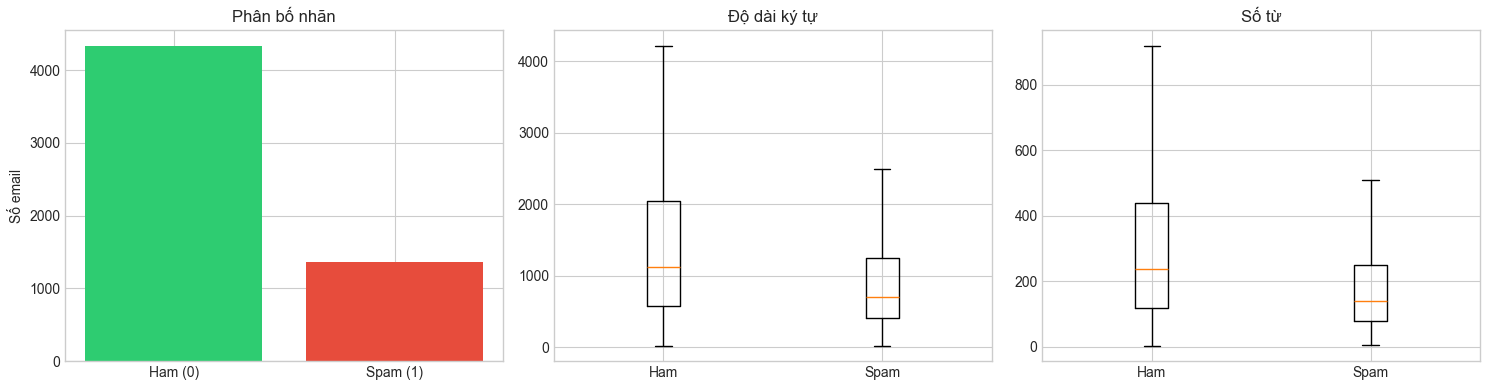

In [4]:
eda_df = clean_df.copy()
eda_df['char_length'] = eda_df['text'].astype(str).str.len()
eda_df['word_count'] = eda_df['text'].astype(str).str.split().str.len()
print(eda_df.groupby('spam')[['char_length', 'word_count']].agg(['mean', 'median']))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
counts = eda_df['spam'].value_counts().sort_index()
axes[0].bar(['Ham (0)', 'Spam (1)'], counts.values, color=['#2ecc71', '#e74c3c'])
axes[0].set_title("Ph\u00e2n b\u1ed1 nh\u00e3n")
axes[0].set_ylabel("S\u1ed1 email")
axes[1].boxplot([eda_df.loc[eda_df.spam == label, 'char_length'] for label in [0, 1]], labels=['Ham', 'Spam'], showfliers=False)
axes[1].set_title("\u0110\u1ed9 d\u00e0i k\u00fd t\u1ef1")
axes[2].boxplot([eda_df.loc[eda_df.spam == label, 'word_count'] for label in [0, 1]], labels=['Ham', 'Spam'], showfliers=False)
axes[2].set_title("S\u1ed1 t\u1eeb")
plt.tight_layout()
plt.show()


### 4.2. Khảo sát Dữ liệu trùng lặp (Duplicates) & Xung đột nhãn trên tập Train


In [5]:
from data.data_processing import clean_and_tokenize

email_mau = 'URGENT: Claim your $1,000 prize at https://example.com'
print("Email m\u1eabu:", email_mau)
print("Token sau ti\u1ec1n x\u1eed l\u00fd:", clean_and_tokenize(email_mau))


Email mẫu: URGENT: Claim your $1,000 prize at https://example.com


Token sau tiền xử lý: ['urgent', 'claim', 'money_amount', 'prize', 'http_url']


### 4.3. Phân tích Độ dài Văn bản (Ký tự & Từ) và Phân vị IQR trên tập Train


In [6]:
def top_words(frame, label, n=10):
    counter = Counter()
    for text in frame.loc[frame['spam'] == label, 'text']:
        counter.update(clean_and_tokenize(text))
    return counter.most_common(n)

for label, name in [(0, 'Ham'), (1, 'Spam')]:
    print(f"{name}: {top_words(clean_df, label)}")


Ham: [('enron', 13329), ('ect', 11410), ('vince', 8468), ('hou', 5567), ('kaminski', 4723), ('com', 4397), ('please', 4332), ('research', 2635), ('thanks', 2509), ('know', 2281)]


Spam: [('com', 999), ('business', 844), ('company', 805), ('email', 804), ('information', 740), ('money', 662), ('free', 606), ('http', 600), ('get', 590), ('mail', 586)]


## Phần 5: Làm sạch Dữ liệu trên cả 3 tập (Dựa trên kết quả EDA từ tập Train)
1. **Xử lý trùng lặp & dữ liệu rỗng:**
   - Tập `Train`: Loại bỏ các email trùng lặp nội dung (`drop_duplicates`) để tránh mô hình học lặp trọng số không cần thiết.
   - Tập `Val` & `Test`: Giữ nguyên tính độc lập, loại bỏ dòng thiếu/rỗng (nếu có).
2. **Tiền xử lý văn bản phi trạng thái (Stateless Text Cleaning - Phương án A):**
   - Áp dụng hàm `clean_and_tokenize(text)` đồng nhất cho cả 3 tập (`df_train`, `df_val`, `df_test`).
   - Chuẩn hóa Meta-tokens: `http_url`, `email_address`, `money_amount`.
   - Chuyển thành chữ thường, loại bỏ dấu câu, loại bỏ stop words, loại bỏ token có độ dài < 3 ký tự (trừ meta-tokens).


In [7]:
vectorizer_params = processed_dir / 'tfidf_vectorizer_params.json'
if vectorizer_params.exists():
    import json
    params = json.loads(vectorizer_params.read_text(encoding='utf-8'))
    print("S\u1ed1 t\u1eeb trong vocabulary:", len(params.get('vocabulary', {})))
    print("C\u1ea5u h\u00ecnh:", {k: params.get(k) for k in ['min_df', 'max_features'] if k in params})
else:
    print("Ch\u01b0a c\u00f3 artifact TF-IDF. H\u00e3y ch\u1ea1y b\u01b0\u1edbc hu\u1ea5n luy\u1ec7n tr\u01b0\u1edbc.")


Số từ trong vocabulary: 2500
Cấu hình: {'min_df': 3, 'max_features': 2500}


## Phần 7: Xây dựng các Mô hình Học Máy từ đầu (Scratch)
1. **Multinomial Naive Bayes:** Phân loại xác suất dựa trên định lý Bayes kết hợp Laplace smoothing.
2. **Logistic Regression:** Phân loại tuyến tính với hàm Sigmoid, tối ưu hóa bằng Gradient Descent với điều chuẩn L2.
3. **Linear SVM:** Tối ưu hóa khoảng cách lề cực đại (Hinge Loss) kết hợp chuẩn hóa L2 qua Gradient Descent.


In [8]:
from train import main as run_training

# Ch\u1ea1y pipeline \u0111\u1ea7y \u0111\u1ee7: chia d\u1eef li\u1ec7u, ti\u1ec1n x\u1eed l\u00fd, TF-IDF, hu\u1ea5n luy\u1ec7n v\u00e0 \u0111\u00e1nh gi\u00e1.
run_training()


BƯỚC 1: ĐỌC DỮ LIỆU & KIỂM TRA CHẤT LƯỢNG BAN ĐẦU


-> Kích thước thô: 5728 dòng, 2 cột
-> Kiểm tra giá trị Null:
 text    0
spam    0
dtype: int64
-> Loại bỏ bản ghi trùng lặp toàn cục: 5728 -> 5695 mẫu (đã xóa 33 bản ghi).
-> Phân bố nhãn sau dedup: Ham=4327 | Spam=1368

BƯỚC 2: PHÂN CHIA DỮ LIỆU STRATIFIED (70% TRAIN / 15% VAL / 15% TEST)


-> Tập Huấn luyện (Train): 3985 mẫu (Ham: 3028, Spam: 957)
-> Tập Kiểm định  (Val)  : 854 mẫu (Ham: 649, Spam: 205)
-> Tập Kiểm thử   (Test) : 856 mẫu (Ham: 650, Spam: 206)
-> Kiểm tra trùng trong Train: 3985 -> 3985 mẫu.

BƯỚC EDA.1: PHÂN BỐ NHÃN SPAM / HAM (TOÀN BỘ DATASET)


-> Đã lưu biểu đồ phân bố nhãn: D:\Năm 3\Máy học\ML_Lab\Lab1 _ Email\reports\figures\spam_distribution.png
   Ham: 4,327 mẫu (75.98%) | Spam: 1,368 mẫu (24.02%)
   Tỷ lệ mất cân bằng Ham:Spam = 3.16:1

BƯỚC EDA.2: PHÂN TÍCH ĐỘ DÀI VĂN BẢN (IQR OUTLIERS & BOXPLOTS) – TRAIN SET


   [Ham] Trung bình: 1634 ký tự / 347 từ | Trung vị: 1112 ký tự / 238 từ
   [Spam] Trung bình: 1329 ký tự / 269 từ | Trung vị: 662 ký tự / 138 từ


-> Đã lưu biểu đồ phân tích độ dài: D:\Năm 3\Máy học\ML_Lab\Lab1 _ Email\reports\figures\text_length_analysis.png

BƯỚC EDA.3: PHÂN TÍCH ĐẶC TRƯNG N-GRAM (TOP BIGRAMS) – TRAIN SET


... (2 outputs left out)

-> Kích thước ma trận TF-IDF: X_train (3985, 2500), X_val (854, 2500), X_test (856, 2500)
-> Top 10 từ khóa phổ biến trong từ điển: ['please', 'vince', 'enron', 'kaminski', 'com', 'thanks', 'know', 'time', 'ect', 'like']

BƯỚC 5: HUẤN LUYỆN 4 MÔ HÌNH FROM SCRATCH TRÊN TẬP TRAIN
-> Multinomial NB            (Th=0.50): Acc=98.71% | Prec=98.99% | Rec=95.61% | F1=97.27%
-> Complement NB             (Th=0.50): Acc=98.71% | Prec=98.99% | Rec=95.61% | F1=97.27%


-> Logistic Regression       (Th=0.50): Acc=96.37% | Prec=98.33% | Rec=86.34% | F1=91.95%


-> Linear SVM                (Th=0.50): Acc=98.83% | Prec=98.03% | Rec=97.07% | F1=97.55%

BẢNG ĐÁNH GIÁ MẪU CƠ SỞ TRÊN TẬP VALIDATION (Threshold = 0.50):
              Model  Accuracy  Precision   Recall  F1-Score  TN  FP  FN  TP
     Multinomial NB  0.987119   0.989899 0.956098  0.972705 647   2   9 196
      Complement NB  0.987119   0.989899 0.956098  0.972705 647   2   9 196
Logistic Regression  0.963700   0.983333 0.863415  0.919481 646   3  28 177
         Linear SVM  0.988290   0.980296 0.970732  0.975490 645   4   6 199

BƯỚC 6: HIỆU CHUẨN NGƯỠNG QUYẾT ĐỊNH (DECISION THRESHOLD CALIBRATION)
-> Quét ngưỡng xác suất trên Validation set từ 0.10 đến 0.90...
-> Ngưỡng quyết định hiệu chuẩn: BEST_THRESHOLD = 0.35 (Validation F1-Score = 97.07%)


-> Đã lưu biểu đồ: D:\Năm 3\Máy học\ML_Lab\Lab1 _ Email\reports\figures\threshold_calibration.png

BƯỚC 7: ĐÁNH GIÁ CHÍNH THỨC TRÊN TẬP TEST ĐỘC LẬP (Threshold = 0.35)
-> Multinomial NB        : Acc=98.36% | Prec=97.52% | Rec=95.63% | F1=96.57% | AUC=0.9962
-> Complement NB         : Acc=98.36% | Prec=97.52% | Rec=95.63% | F1=96.57% | AUC=0.9962
-> Logistic Regression   : Acc=98.01% | Prec=95.22% | Rec=96.60% | F1=95.90% | AUC=0.9964
-> Linear SVM            : Acc=95.68% | Prec=85.36% | Rec=99.03% | F1=91.69% | AUC=0.9977

BẢNG SO SÁNH HIỆU NĂNG ĐẦY ĐỦ TRÊN TẬP KIỂM THỬ ĐỘC LẬP (TEST SET):
    Model Algorithm  Accuracy  Precision   Recall  F1-Score  ROC-AUC  TN  FP  FN  TP
     Multinomial NB  0.983645   0.975248 0.956311  0.965686 0.996169 645   5   9 197
      Complement NB  0.983645   0.975248 0.956311  0.965686 0.996169 645   5   9 197
Logistic Regression  0.980140   0.952153 0.966019  0.959036 0.996408 640  10   7 199
         Linear SVM  0.956776   0.853556 0.990291  0.916854 0.9

## Phần 9: Tinh chỉnh ngưỡng quyết định (Threshold Tuning) trên tập Validation

Mặc định, ngưỡng phân loại xác suất là $0.5$. Chúng ta quét ngưỡng từ $0.1$ đến $0.9$ trên **tập Validation** để tìm ra ngưỡng tối ưu hóa F1-Score, cân bằng giữa Precision và Recall.


In [9]:
results = pd.read_csv(PROJECT_ROOT / 'data' / 'processed' / 'evaluation_results.csv')
print("K\u1ebft qu\u1ea3 \u0111\u00e1nh gi\u00e1:")
try:
    display(results)
except NameError:
    print(results.to_string(index=False))


Kết quả đánh giá:


,Model Algorithm,Accuracy,Precision,Recall,F1-Score,ROC-AUC,TN,FP,FN,TP
0,Multinomial NB,0.983645,0.975248,0.956311,0.965686,0.996169,645,5,9,197
1,Complement NB,0.983645,0.975248,0.956311,0.965686,0.996169,645,5,9,197
2,Logistic Regression,0.980140,0.952153,0.966019,0.959036,0.996408,640,10,7,199
3,Linear SVM,0.956776,0.853556,0.990291,0.916854,0.997655,615,35,2,204


In [10]:
from predict import StatelessSpamClassifier

classifier = StatelessSpamClassifier(str(PROJECT_ROOT / 'models' / 'email_classifier.json'))
examples = [
    'Urgent: You won $1,000,000 cash. Click here now!',
    'Team meeting tomorrow at 10 AM. Please review the report.'
]
for email in examples:
    prediction = classifier.predict(email)
    print("Email:", email)
    print("Nh\u00e3n:", prediction['label'])
    print(f"X\u00e1c su\u1ea5t Spam: {prediction['spam_probability']:.2%}")
    print("T\u1eeb k\u00edch ho\u1ea1t:", prediction['top_trigger_words'])


[*] Đang nạp mô hình JSON từ: D:\Năm 3\Máy học\ML_Lab\Lab1 _ Email\models\email_classifier.json...
[+] Đã khôi phục thành công mô hình: MultinomialNaiveBayesScratch (Ngưỡng kích hoạt: 0.35)
Email: Urgent: You won $1,000,000 cash. Click here now!
Nhãn: 🚨 SPAM (THƯ RÁC)
Xác suất Spam: 86.40%
Từ kích hoạt: ['click', 'cash', 'now', 'money_amount', 'won']
Email: Team meeting tomorrow at 10 AM. Please review the report.
Nhãn: ✅ HAM (THƯ HỢP LỆ)
Xác suất Spam: 1.01%
Từ kích hoạt: ['meeting', 'tomorrow', 'review', 'team', 'please']
